# Brightness temperature vs ADU

Put saved system response NPZ files in **SystemResponses** and ND + beamsplitter files in **TransmissionFilters**. Run the cells below in order. The plot and CSV are saved in **Outputs**.

In VS Code, select your Python kernel. If packages are missing, run `%pip install numpy pandas matplotlib openpyxl` in a temporary notebook cell once, then restart the kernel.

## 1. Setup
Sets up numerous helper functions and imports python packages

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def interpolate_transmission(wavelength, values, output_wavelength, in_percent):
    wavelength = np.asarray(wavelength, dtype=float)
    values = np.asarray(values, dtype=float)
    valid = np.isfinite(wavelength) & np.isfinite(values)
    wavelength, values = wavelength[valid], values[valid]
    order = np.argsort(wavelength)
    wavelength, values = wavelength[order], values[order]
    if len(wavelength) < 2 or np.any(np.diff(wavelength) <= 0):
        raise ValueError("Transmission data need at least two distinct, increasing wavelengths.")
    if in_percent:
        values = values / 100.0
    if np.any((values < 0) | (values > 1)):
        raise ValueError("Transmission is outside 0–1. Check the percent/fraction setting.")
    if output_wavelength[0] < wavelength[0] or output_wavelength[-1] > wavelength[-1]:
        print("Note: transmission does not cover the full response grid; holding endpoint values, as in the original notebook.")
    return np.interp(output_wavelength, wavelength, values)


def load_nd_filters(path, output_wavelength, in_percent):
    # Original ND TXT format: first row = numeric ND labels; subsequent rows
    # contain wavelength/transmission pairs for each filter, separated by tabs.
    lines = [line for line in Path(path).read_text(encoding="utf-8-sig").splitlines() if line.strip()]
    labels = [f"{float(value):.2f}" for value in lines[0].split("\t") if value.strip()]
    if len(set(labels)) != len(labels):
        raise ValueError("ND filter labels must be unique.")
    rows = {label: [] for label in labels}
    for line in lines[1:]:
        values = line.split("\t")
        for i, label in enumerate(labels):
            pair = values[2*i:2*i+2]
            if len(pair) != 2 or not all(value.strip() for value in pair):
                continue
            try:
                rows[label].append(tuple(map(float, pair)))
            except ValueError:
                continue  # Skip optional nonnumeric column headings.
    curves = {}
    for label, pairs in rows.items():
        if len(pairs) < 2:
            raise ValueError(f"No usable transmission curve for ND {label}.")
        wavelength, transmission = np.asarray(pairs).T
        curves[label] = interpolate_transmission(wavelength, transmission, output_wavelength, in_percent)
    return curves


def load_beamsplitter(path, output_wavelength, in_percent):
    # Original Excel format: sheet 'Splitter', wavelength and reflected columns.
    raw = pd.read_excel(path, sheet_name="Splitter", header=None)
    for row in range(len(raw)):
        names = [str(value).strip().lower() for value in raw.iloc[row]]
        wave_columns = [i for i, name in enumerate(names) if "wave" in name or "lambda" in name]
        reflected_columns = [i for i, name in enumerate(names) if "reflect" in name]
        if wave_columns and reflected_columns:
            data = raw.iloc[row+1:, [wave_columns[0], reflected_columns[0]]]
            data = data.apply(pd.to_numeric, errors="coerce").dropna().to_numpy()
            return interpolate_transmission(data[:, 0], data[:, 1], output_wavelength, in_percent)
    raise ValueError("The Splitter sheet needs wavelength and reflection/reflected columns.")


def planck_radiance(wavelength_nm, temperature_k):
    # Spectral radiance in mW cm^-2 nm^-1 sr^-1.
    h, c, k = 6.62607015e-34, 2.99792458e8, 1.380649e-23
    wavelength_m = wavelength_nm * 1e-9
    with np.errstate(over="ignore"):
        return (2*h*c**2 / wavelength_m**5
                / np.expm1(h*c / (wavelength_m*k*temperature_k))) * 1e-10

## 2. Choose system response
Change the filename below to the NPZ you want to use.

In [3]:
RESPONSE_FILE = Path("SystemResponses/EP2021SystemResponse.npz")

with np.load(RESPONSE_FILE, allow_pickle=False) as data:
    if "experiment_nd_filters" in data.files or "system_response_samples" in data.files:
        raise ValueError("Choose absolute_calibrated_system_response.npz, not the experimental response or GP posterior.")
    wavelength_nm = np.asarray(data["wavelength_nm"], dtype=float)
    response_samples = np.asarray(data["response_samples"], dtype=float)
    if "response_units" in data.files:
        if str(data["response_units"].item()) != "ADU/ns/(mW cm^-2 sr^-1)":
            raise ValueError("Expected response units ADU/ns/(mW cm^-2 sr^-1).")
if response_samples.ndim == 1:
    response_samples = response_samples[None, :]
if (wavelength_nm.ndim != 1 or len(wavelength_nm) < 2
        or np.any(~np.isfinite(wavelength_nm)) or np.any(wavelength_nm <= 0)
        or np.any(np.diff(wavelength_nm) <= 0)):
    raise ValueError("The response wavelength grid must be finite, positive, and increasing.")
if (response_samples.ndim != 2 or response_samples.shape[1] != len(wavelength_nm)
        or len(response_samples) == 0 or np.any(~np.isfinite(response_samples))
        or np.any(response_samples < 0)):
    raise ValueError("Response samples must be finite, nonnegative, and shaped (draws, wavelengths).")
print(f"Loaded {RESPONSE_FILE.name}: {len(response_samples)} response curves.")

Loaded EP2021SystemResponse.npz: 5000 response curves.


## 3. Choose ND filters, beamsplitter, and emissivity

Ensure that any replacements to the original transmission files follow the same strucutre to avoid errors.

Use `ND_FILTERS = []` for no ND filters. Set sweep duration and time-pixel count for your experiment.

In [4]:
ND_FILE = Path("TransmissionFilters/ND_TransmissionsEP.txt")
ND_FILTERS = []                       # e.g. [0.30, 1.00]
ND_IN_PERCENT = True

USE_BEAMSPLITTER = False
BEAMSPLITTER_FILE = Path("TransmissionFilters/beamsplitterTransmission.xlsx")
BEAMSPLITTER_IN_PERCENT = True

EMISSIVITY = 1.0
SWEEP_DURATION_NS = 17.0 #Sweep duration in nanoseconds
TIME_PIXEL_COUNT = 1024 

TEMPERATURE_MIN_K = 1.0  #Temperatures in Kelvin
TEMPERATURE_MAX_K = 100000.0  
TEMPERATURE_POINTS = 1024
ADU_LIMITS = None                     # e.g. (0, 150)
TEMPERATURE_EV_LIMITS = None          # e.g. (0, 0.5)
OUTPUT_NAME = "brightness_temperature_vs_adu"  # change to keep separate plots

nd_transmission = np.ones_like(wavelength_nm)
if ND_FILTERS:
    nd_curves = load_nd_filters(ND_FILE, wavelength_nm, ND_IN_PERCENT)
    print("Available ND filters:", list(nd_curves))
    for value in ND_FILTERS:
        label = f"{float(value):.2f}"
        if label not in nd_curves:
            raise ValueError(f"ND {label} not found. Available: {list(nd_curves)}")
        nd_transmission *= nd_curves[label]

splitter = (load_beamsplitter(BEAMSPLITTER_FILE, wavelength_nm, BEAMSPLITTER_IN_PERCENT)
            if USE_BEAMSPLITTER else np.ones_like(wavelength_nm))
print("ND filters:", ND_FILTERS or "none", "| Beamsplitter:", USE_BEAMSPLITTER,
      "| Emissivity:", EMISSIVITY)

ND filters: none | Beamsplitter: False | Emissivity: 1.0


## 4. Plot brightness temperature vs ADU

Saves a PNG and CSV in **Outputs**. Rerunning with the same `OUTPUT_NAME` replaces them. After changing settings, rerun the settings cell and this cell.

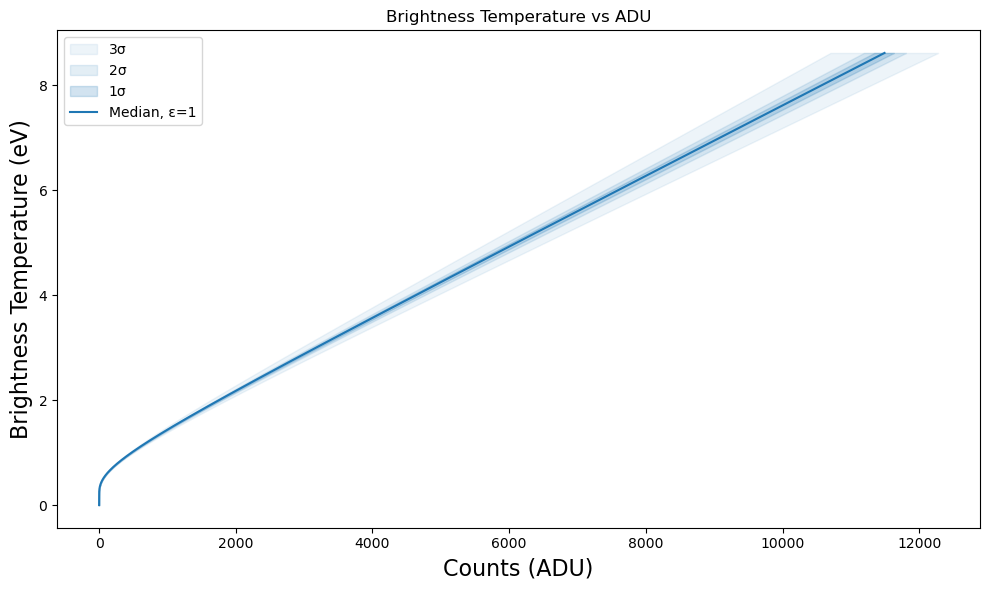

Saved Outputs/brightness_temperature_vs_adu.png and Outputs/brightness_temperature_vs_adu.csv


In [5]:
if not np.isfinite(EMISSIVITY) or not 0 < EMISSIVITY <= 1:
    raise ValueError("Emissivity must be in (0, 1].")
if not np.isfinite(SWEEP_DURATION_NS) or SWEEP_DURATION_NS <= 0 or TIME_PIXEL_COUNT <= 0:
    raise ValueError("Sweep duration and time-pixel count must be positive.")
if not (0 < TEMPERATURE_MIN_K < TEMPERATURE_MAX_K) or TEMPERATURE_POINTS < 2:
    raise ValueError("Choose a positive temperature range with at least two points.")

temperature_k = np.linspace(TEMPERATURE_MIN_K, TEMPERATURE_MAX_K, TEMPERATURE_POINTS)
temperature_ev = temperature_k / 11604.51812
responses = response_samples * nd_transmission * splitter
if np.any(np.max(responses, axis=1) <= 0):
    raise ValueError("The selected optics leave zero response for at least one curve.")

# Same reproducible limit as the original notebook, to keep memory use manageable.
if len(responses) > 5000:
    indices = np.sort(np.random.default_rng(12345).choice(len(responses), 5000, replace=False))
    responses = responses[indices]

spacing = np.diff(wavelength_nm)
weights = np.r_[spacing[0]/2, (spacing[:-1]+spacing[1:])/2, spacing[-1]/2]
weighted_responses = responses * weights
percentiles = [0.13498980316301035, 2.275013194817921, 15.865525393145708,
               50.0, 84.1344746068543, 97.72498680518208, 99.86501019683699]
bands = np.empty((7, len(temperature_k)))
for start in range(0, len(temperature_k), 128):
    stop = min(start+128, len(temperature_k))
    radiance = planck_radiance(wavelength_nm[None, :], temperature_k[start:stop, None])
    counts = (SWEEP_DURATION_NS / TIME_PIXEL_COUNT * EMISSIVITY * radiance) @ weighted_responses.T
    bands[:, start:stop] = np.percentile(counts, percentiles, axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
if len(responses) > 1:
    for lo, hi, sigma, alpha in [(0, 6, 3, .08), (1, 5, 2, .12), (2, 4, 1, .20)]:
        ax.fill_betweenx(temperature_ev, bands[lo], bands[hi],
                         color="tab:blue", alpha=alpha, label=f"{sigma}σ")
ax.plot(bands[3], temperature_ev, color="tab:blue", label=f"Median, ε={EMISSIVITY:g}")
ax.set_xlabel("Counts (ADU)", fontsize=16)
ax.set_ylabel("Brightness Temperature (eV)" if EMISSIVITY == 1
              else "Temperature for assumed emissivity (eV)", fontsize=16)
ax.set_title("Brightness Temperature vs ADU" if EMISSIVITY == 1
             else "Emissivity-corrected Temperature vs ADU")
if ADU_LIMITS is not None:
    ax.set_xlim(ADU_LIMITS)
if TEMPERATURE_EV_LIMITS is not None:
    ax.set_ylim(TEMPERATURE_EV_LIMITS)
ax.legend()
fig.tight_layout()

output_folder = Path("Outputs")
output_folder.mkdir(exist_ok=True)
fig.savefig(output_folder / f"{OUTPUT_NAME}.png", dpi=300, bbox_inches="tight")
plt.show()

table = pd.DataFrame({"temperature_k": temperature_k, "temperature_ev": temperature_ev})
for name, values in zip(["3sigma_lower", "2sigma_lower", "1sigma_lower", "median",
                         "1sigma_upper", "2sigma_upper", "3sigma_upper"], bands):
    table[f"adu_{name}"] = values
table.to_csv(output_folder / f"{OUTPUT_NAME}.csv", index=False)
print(f"Saved Outputs/{OUTPUT_NAME}.png and Outputs/{OUTPUT_NAME}.csv")